# CDC HDP-proxy · отложенная важность признаков

На воспроизводимой 5% подвыборке каждого отложенного фолда считаем изменение AUPRC и Brier при трёх независимых перестановках. BMI и показатели анамнеза переставляются **вместе со своей маской пропуска**; отдельно проверяются семейства возраста/BMI и предыдущих беременностей. Маска сама по себе не переставляется, потому что это создало бы невозможные пары «значение известно, маска=1». Добавочную ценность масок проверяет `hist_gb_no_masks` в 06. Это важность для **данной обученной модели и записанной метки**, не причинный эффект. Сначала запустите 02. Обучения здесь нет.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/data/preeclampsia_cdc.py").exists())
sys.path.insert(0, str(ROOT))
from src.progress import tqdm
plt.rcParams.update({"figure.figsize": (8, 4.8), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .2})
BLUE, ORANGE, GREY = "#255B8B", "#D17A31", "#666D78"
MODEL_PALETTE = [("logistic_spline", BLUE), ("hist_gb", ORANGE),
                 ("catboost", "#287D69"), ("lightgbm", "#8062A5")]
RACE6 = {1:"White",2:"Black",3:"AIAN",4:"Asian",5:"NHOPI",6:"Multiple"}  # NCHS MRACE6; social reporting categories
import joblib, gc
from src.data.preeclampsia_cdc import OUT, ROOT, FEATURES
from src.training.preeclampsia_cdc import MODEL_DIR, SPLINE_FEATURES, run_fingerprint
from src.evaluation.preeclampsia_cdc_features import analysis_sample, heldout_permutation_importance

/Users/nick/Desktop/projects/femfedora/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
manifest=json.loads((OUT/"fold_run.json").read_text())
assert manifest["fingerprint"]==run_fingerprint()
sample=analysis_sample(fraction=.05)
display(sample.groupby("fold").target_hdp_proxy.agg(["size","sum","mean"]).round(4))

,size,sum,mean
fold,,,
0,67814,7203,0.1062
1,67546,7161,0.1060
2,67337,7098,0.1054
3,67624,7216,0.1067
4,67540,7339,0.1087


In [3]:
parts=[]
for fold in tqdm(range(5),desc="Held-out importance",unit="fold"):
    heldout=sample.loc[sample.fold.eq(fold)].copy()
    for name, features in [(name, SPLINE_FEATURES if name=="logistic_spline" else FEATURES) for name,_ in MODEL_PALETTE]:
        model=joblib.load(MODEL_DIR/f"fold_{fold}_{name}.joblib")
        groups={"previous_pregnancy_history":[x for x in ["prior_live_birth_count_cat","prior_live_birth_count_missing","priorterm","priorterm_missing","rf_ppterm","rf_cesar"] if x in features],"age_bmi_family":[x for x in ["mager","bmi","bmi_missing"] if x in features]}
        parts.append(heldout_permutation_importance(model,heldout,features,name,fold,repeats=3,groups=groups))
        del model
    gc.collect()
importance=pd.concat(parts,ignore_index=True)
importance.to_csv(OUT/"heldout_feature_importance.csv",index=False)
display(importance.head().round(5))

Held-out importance: 100%|██████████| 5/5 [00:24<00:00,  4.93s/fold]


,fold,model,feature,feature_kind,members,repeat,sample_rows,sample_events,baseline_auprc,baseline_brier,delta_auprc,delta_brier
0,0,logistic_spline,mager,individual,mager,0,67814,7203,0.1905,0.09159,0.00480,0.00028
1,0,logistic_spline,mager,individual,mager,1,67814,7203,0.1905,0.09159,0.00386,0.00023
2,0,logistic_spline,mager,individual,mager,2,67814,7203,0.1905,0.09159,0.00484,0.00028
3,0,logistic_spline,bmi,individual,"bmi,bmi_missing",0,67814,7203,0.1905,0.09159,0.06386,0.00468
4,0,logistic_spline,bmi,individual,"bmi,bmi_missing",1,67814,7203,0.1905,0.09159,0.06485,0.00478


delta_auprc           \
                                                               mean      std   
model           feature_kind feature                                           
catboost        group        age_bmi_family                 0.07103  0.00295   
                             previous_pregnancy_history     0.03424  0.00179   
                individual   bmi                            0.06893  0.00413   
                             mager                          0.00582  0.00116   
                             prior_live_birth_count_cat     0.02864  0.00203   
                             priorterm                      0.00098  0.00028   
                             rf_cesar                       0.00121  0.00044   
                             rf_pdiab                       0.00497  0.00072   
                             rf_ppterm                      0.00574  0.00067   
hist_gb         group        age_bmi_family                 0.07026  0.00289   
                             previous_pregnancy_history     0.03392  0.00199   
                individual   bmi                            0.06826  0.00405   
                             mager                          0.00555  0.00099   
                             prior_live_birth_count_cat     0.02942  0.00235   
                             priorterm                      0.00092  0.00021   
                             rf_cesar                       0.00061  0.00024   
                             rf_pdiab                       0.00528  0.00074   
                             rf_ppterm                      0.00566  0.00059   
lightgbm        group        age_bmi_family                 0.07063  0.00303   
                             previous_pregnancy_history     0.03405  0.00197   
                individual   bmi                            0.06849  0.00432   
                             mager                          0.00590  0.00116   
                             prior_live_birth_count_cat     0.02883  0.00224   
                             priorterm                      0.00099  0.00029   
                             rf_cesar                       0.00091  0.00038   
                             rf_pdiab                       0.00531  0.00067   
                             rf_ppterm                      0.00577  0.00050   
logistic_spline group        age_bmi_family                 0.06931  0.00281   
                             previous_pregnancy_history     0.03323  0.00177   
                individual   bmi                            0.06787  0.00397   
                             mager                          0.00394  0.00127   
                             prior_live_birth_count_cat     0.03104  0.00237   
                             priorterm                      0.00092  0.00046   
                             rf_cesar                      -0.00000  0.00001   
                             rf_pdiab                       0.00427  0.00086   
                             rf_ppterm                      0.00754  0.00099   

                                                        delta_brier           
                                                               mean      std  
model           feature_kind feature                                          
catboost        group        age_bmi_family                 0.00534  0.00013  
                             previous_pregnancy_history     0.00247  0.00009  
                individual   bmi                            0.00499  0.00023  
                             mager                          0.00034  0.00006  
                             prior_live_birth_count_cat     0.00212  0.00011  
                             priorterm                      0.00006  0.00001  
                             rf_cesar                       0.00007  0.00002  
                             rf_pdiab                       0.00022  0.00002  
                             rf_ppterm                      0.0003

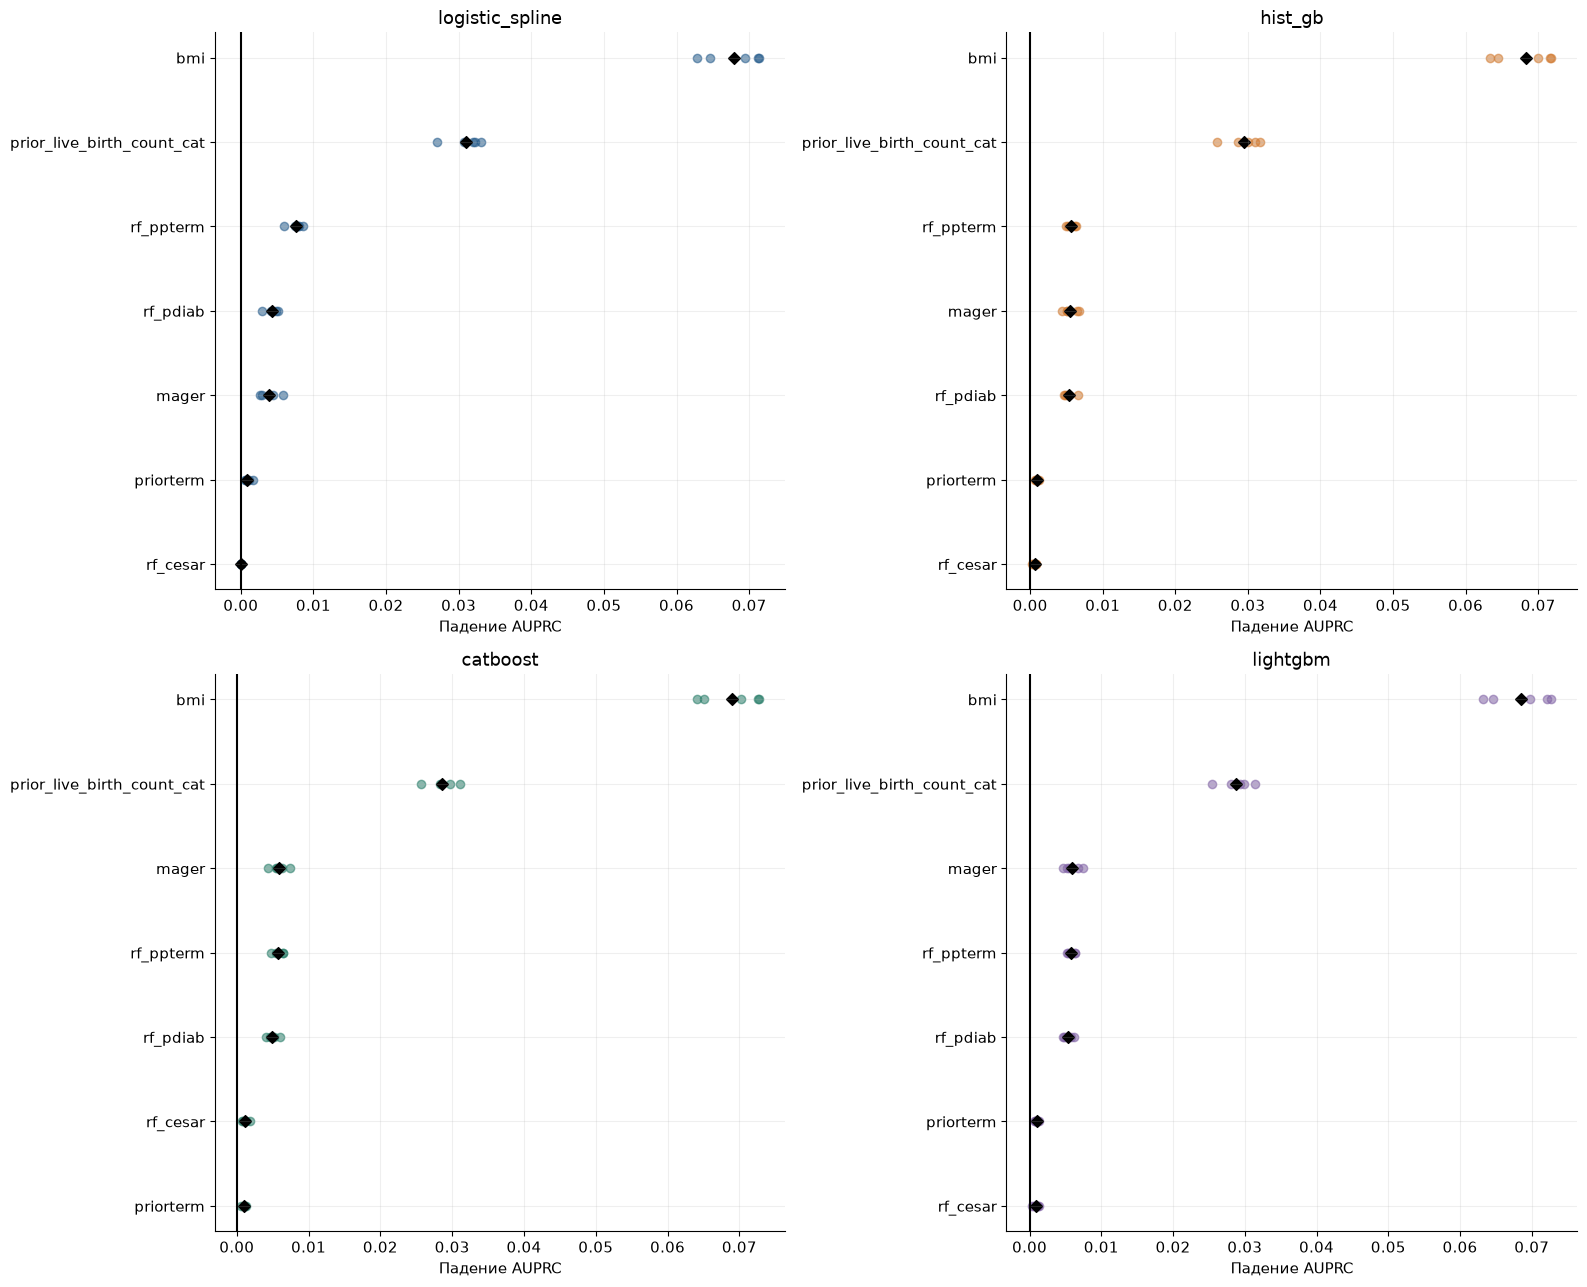

In [4]:
fold_means=importance.groupby(["model","feature_kind","feature","fold"],as_index=False)[["delta_auprc","delta_brier"]].mean()
summary=fold_means.groupby(["model","feature_kind","feature"])[["delta_auprc","delta_brier"]].agg(["mean","std"])
display(summary.round(5))
fig,axes=plt.subplots(2,2,figsize=(16,13))
for ax,(name,color) in zip(axes.flat,MODEL_PALETTE):
    part=fold_means.loc[fold_means.model.eq(name)&fold_means.feature_kind.eq("individual")]
    order=part.groupby("feature").delta_auprc.mean().sort_values().index
    for index,feature in enumerate(order):
        vals=part.loc[part.feature.eq(feature)].delta_auprc.to_numpy()
        ax.scatter(vals,np.full(len(vals),index),color=color,alpha=.55)
        ax.scatter(vals.mean(),index,marker="D",color="black")
    ax.set_yticks(range(len(order)),order);ax.axvline(0,color="black")
    ax.set(xlabel="Падение AUPRC",title=name)
plt.tight_layout();plt.show()

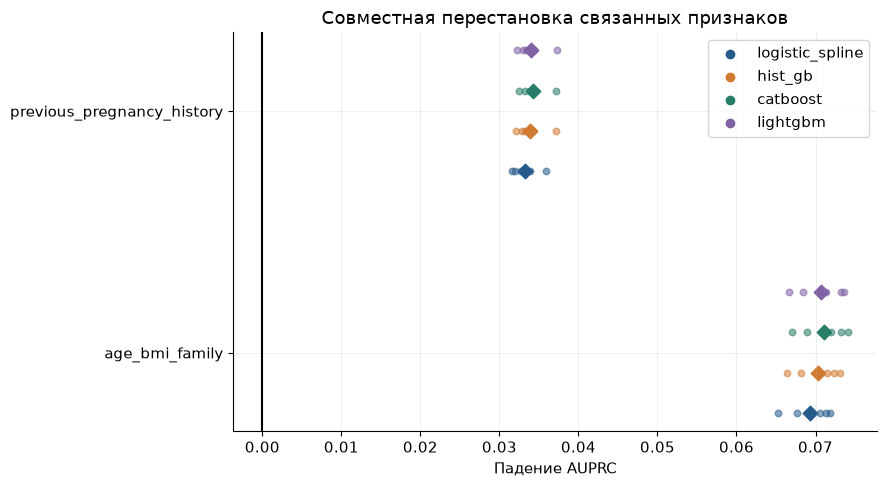

In [5]:
grouped=fold_means.loc[fold_means.feature_kind.eq("group")]
if not grouped.empty:
    fig,ax=plt.subplots(figsize=(9,5))
    group_order=sorted(grouped.feature.unique())
    for offset,(name,color) in zip(np.linspace(-.25,.25,len(MODEL_PALETTE)),MODEL_PALETTE):
        part=grouped.loc[grouped.model.eq(name)]
        for index,feature in enumerate(group_order):
            vals=part.loc[part.feature.eq(feature)].delta_auprc.to_numpy()
            ax.scatter(vals,np.full(len(vals),index+offset),color=color,alpha=.55,s=22)
            ax.scatter(vals.mean(),index+offset,marker="D",color=color,s=55)
        ax.scatter([],[],color=color,label=name)
    ax.set_yticks(range(len(group_order)),group_order);ax.axvline(0,color="black")
    ax.set(xlabel="Падение AUPRC",title="Совместная перестановка связанных признаков")
    ax.legend();plt.tight_layout();plt.show()

## Усреднённые кривые зависимости возраста и BMI

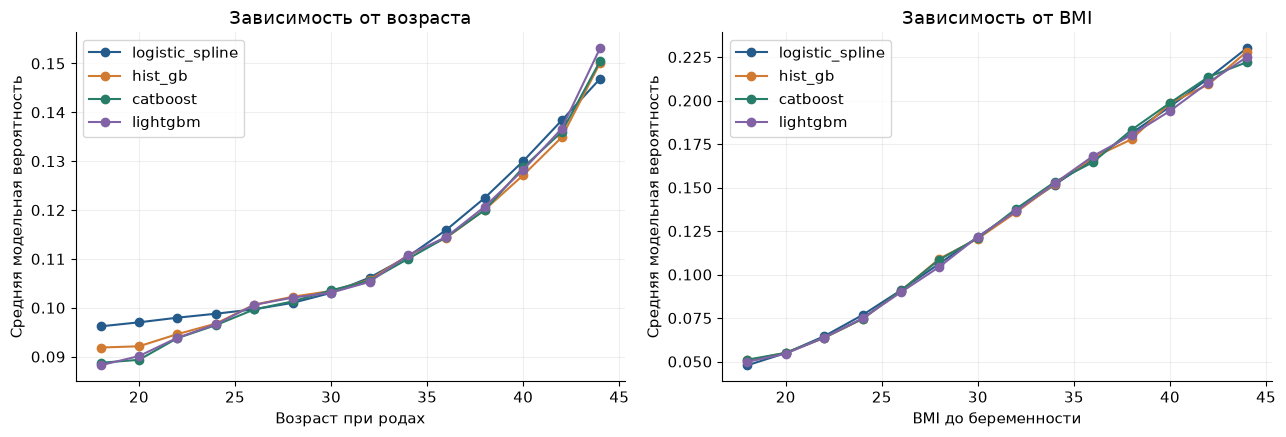

In [6]:
heldout=sample.loc[sample.fold.eq(0)].sample(n=min(5000,int(sample.fold.eq(0).sum())),random_state=20261001).copy()
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
for name,color in MODEL_PALETTE:
    model=joblib.load(MODEL_DIR/f"fold_0_{name}.joblib")
    features=SPLINE_FEATURES if name=="logistic_spline" else FEATURES
    for ax,feature,grid in [(axes[0],"mager",np.arange(18,46,2)),(axes[1],"bmi",np.arange(18,46,2))]:
        values=[]
        for value in tqdm(grid,desc=f"{name} {feature}",leave=False):
            changed=heldout[features].copy();changed[feature]=value
            if feature=="bmi": changed["bmi_missing"]=0
            p=model.predict_proba(changed)[:,1]
            values.append(p.mean())
        ax.plot(grid,values,marker="o",label=name,color=color)
    del model
axes[0].set(xlabel="Возраст при родах",ylabel="Средняя модельная вероятность",title="Зависимость от возраста")
axes[1].set(xlabel="BMI до беременности",ylabel="Средняя модельная вероятность",title="Зависимость от BMI")
for ax in axes:ax.legend()
plt.tight_layout();plt.show()

Усреднённые кривые меняют один вход модели на фиксированной подвыборке и могут создавать нереалистичные сочетания признаков; это диагностический график модели. Разброс перестановочной важности по пяти фолдам и повторам не следует называть доверительным интервалом. Для клинической интерпретации учитывайте неполную метку, неучтённый аспирин и возможную общую ошибку регистрации факторов и исхода. Перестановочная важность не превращает коэффициенты штрафной логистики в клинические OR.